In [1]:
import boto3
import sagemaker
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

sns.set_theme()

sess = sagemaker.Session()
bucket = sess.default_bucket()
role = sagemaker.get_execution_role()
region = boto3.Session().region_name

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


In [2]:
%store -r
%store

Stored variables and their in-db values:
alarm_names                                -> ['cls-f1-141e5d13', 'cls-input-brightness-drift-14
baseline_prefix                            -> 'cat-landmarks-project/monitoring/f0d83606-c3c6-4b
bucket                                     -> 'sagemaker-us-east-1-298748835671'
cls_drift_schedule                         -> 'cls-drift-hourly-141e5d13'
cls_endpoint_name                          -> 'cls-f0d83606-c3c6-4b88-a55b-63efac0bccfc'
cls_model_data_url                         -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
cls_model_package_arn                      -> 'arn:aws:sagemaker:us-east-1:298748835671:model-pa
cls_quality_schedule                       -> 'cls-quality-hourly-141e5d13'
data_capture_prefix                        -> 'cat-landmarks-project/monitoring/f0d83606-c3c6-4b
database_name                              -> 'cat_landmarking'
ingest_create_athena_db_passed             -> True
ingestion_completed                    

In [3]:
ingest_create_athena_db_passed = False

In [4]:
# Restore project S3 paths created during ingestion
project_prefix = project_prefix
s3_raw_cats_prefix = s3_raw_cats_prefix
s3_raw_noncats_prefix = s3_raw_noncats_prefix
s3_processed_combined_prefix = s3_processed_combined_prefix
s3_processed_cats_prefix = s3_processed_cats_prefix

print("Cats:", s3_raw_cats_prefix)
print("Noncats:", s3_raw_noncats_prefix)
print("Processed/combined:", s3_processed_combined_prefix)
print("Processed/cats:", s3_processed_cats_prefix)

Cats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/raw/cats/
Noncats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/raw/noncats/noncat_images/
Processed/combined: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/processed/combined/
Processed/cats: s3://sagemaker-us-east-1-298748835671/cat-landmarks-project/data/processed/cats/


# Setting up Athena

In [5]:
database_name = "cat_landmarking"
manifest_table = "image_manifest"
landmarks_table = "cat_annotations"

s3_staging_dir = f"s3://{bucket}/{project_prefix}/athena/staging/"

engine = create_engine(
    f"awsathena+rest://@athena.{region}.amazonaws.com:443/"
    f"{database_name}"
    f"?s3_staging_dir={s3_staging_dir}"
)

# Create Database

In [6]:
statement = f"CREATE DATABASE IF NOT EXISTS {database_name}"
pd.read_sql(statement, engine)

""


In [7]:
# Clean up this project's tables from previous runs. Dropping tables rather than the whole
# database needs only glue:DeleteTable, and other databases in the account are untouched.
for table in (landmarks_table, manifest_table):
    pd.read_sql(f"DROP TABLE IF EXISTS {database_name}.{table}", engine)

In [8]:
statement = "SHOW DATABASES"
pd.read_sql(statement, engine)

,database_name
0,cat_landmarking
1,default
2,room_metadata
3,sagemaker_featurestore


# Create Cat Annotations Table

In [9]:
# Creating landmarks table
s3_landmarks_location = f"{s3_processed_cats_prefix}/annotations"

statement_landmarks_table_spec = f"""
CREATE EXTERNAL TABLE IF NOT EXISTS {database_name}.{landmarks_table} (

    remote_path        VARCHAR(1024),
    local_path         VARCHAR(1024),

    left_eye           ARRAY<INT>,
    right_eye          ARRAY<INT>,
    mouth              ARRAY<INT>,
    left_ear_1         ARRAY<INT>,
    left_ear_2         ARRAY<INT>,
    left_ear_3         ARRAY<INT>,
    right_ear_1        ARRAY<INT>,
    right_ear_2        ARRAY<INT>,
    right_ear_3        ARRAY<INT>,

    version            VARCHAR(64),
    split              VARCHAR(32),

    left_eye_x         BIGINT,
    left_eye_y         BIGINT,
    right_eye_x        BIGINT,
    right_eye_y        BIGINT,
    mouth_x            BIGINT,
    mouth_y            BIGINT,
    left_ear_1_x       BIGINT,
    left_ear_1_y       BIGINT,
    left_ear_2_x       BIGINT,
    left_ear_2_y       BIGINT,
    left_ear_3_x       BIGINT,
    left_ear_3_y       BIGINT,
    right_ear_1_x      BIGINT,
    right_ear_1_y      BIGINT,
    right_ear_2_x      BIGINT,
    right_ear_2_y      BIGINT,
    right_ear_3_x      BIGINT,
    right_ear_3_y      BIGINT,

    file_size          BIGINT,
    width              BIGINT,
    height             BIGINT,
    label              BIGINT
)
STORED AS PARQUET
LOCATION '{s3_landmarks_location}'
"""

pd.read_sql(statement_landmarks_table_spec, engine)

""


# Create Manifest Table

In [10]:
# Create manifest table
s3_metadata_location = f"{s3_processed_combined_prefix}/metadata"

pd.read_sql(f"DROP TABLE IF EXISTS {database_name}.{manifest_table}",
            engine)

statement_manifest_table_spec = f"""
CREATE EXTERNAL TABLE IF NOT EXISTS {database_name}.{manifest_table} (
    remote_path    STRING,
	local_path     STRING,
	file_size      BIGINT,
	width          BIGINT,
	height         BIGINT,
	label          BIGINT,
	source         STRING,
	version        STRING,
	split          STRING,
	ingest_time    STRING
)
STORED AS PARQUET
LOCATION '{s3_metadata_location}'
"""

pd.read_sql(statement_manifest_table_spec, engine)

""


# Checking Ingestion

In [11]:
# Show tables in database
pd.read_sql(f"SHOW TABLES FROM {database_name}", engine)

,tab_name
0,cat_annotations
1,image_manifest


In [12]:
# Inspect head of manifest table
pd.read_sql(f"SELECT * FROM {database_name}.{manifest_table} LIMIT 5", engine)

,remote_path,local_path,file_size,width,height,label,source,version,split,ingest_time
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,62243,375,500,1,kaggle_cats,raw,production,2026-10-12T02:53:16.548819
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,53666,500,375,1,kaggle_cats,raw,production,2026-10-12T02:53:16.548819
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,82126,500,375,1,kaggle_cats,raw,train,2026-10-12T02:53:16.548819
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,72563,500,375,1,kaggle_cats,raw,train,2026-10-12T02:53:16.548819
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,41115,500,333,1,kaggle_cats,raw,train,2026-10-12T02:53:16.548819


In [13]:
# Inspect head of landmarks table
pd.read_sql(f"SELECT * FROM {database_name}.{landmarks_table} LIMIT 5", 
            engine)

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_size,width,height,label
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,281,101,312,96,296,133,62243,375,500,1
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,270,90,353,35,332,147,72563,500,375,1
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,233,39,281,9,224,69,41115,500,333,1
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,210,52,260,63,229,121,53666,500,375,1
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,341,197,359,183,361,203,82126,500,375,1


In [14]:
ingest_create_athena_db_passed = True

In [15]:
%store ingest_create_athena_db_passed

Stored 'ingest_create_athena_db_passed' (bool)


# EDA

In [16]:
# Image counts by source and label (1 = cat, 0 = non-cat)
statement_label_counts = f"""
SELECT source, label, COUNT(*) AS n
FROM {database_name}.{manifest_table}
GROUP BY source, label
ORDER BY source, label
"""
pd.read_sql(statement_label_counts, engine)

,source,label,n
0,coco,0,15000
1,coco,1,4112
2,kaggle_cats,1,17884
3,oxford_pets,0,4978
4,oxford_pets,1,2371


In [17]:
# Classifier splits: original images only (augmented cat images are for the keypoint model)
statement_split_counts = f"""
SELECT split, label, COUNT(*) AS n
FROM {database_name}.{manifest_table}
WHERE version = 'raw'
GROUP BY split, label
ORDER BY split, label
"""

pd.read_sql(statement_split_counts, engine)

,split,label,n
0,production,0,7993
1,production,1,6571
2,test,0,1997
3,test,1,1641
4,train,0,7991
5,train,1,6566
6,validation,0,1997
7,validation,1,1641


In [18]:
# File size by source and label. All images were re-encoded at the same JPEG quality
# during ingestion, so remaining differences come from resolution and content.
statement_file_size = f"""
SELECT
  source,
  label,
  MIN(file_size) AS min_bytes,
  APPROX_PERCENTILE(file_size, 0.5) AS p50_bytes,
  APPROX_PERCENTILE(file_size, 0.95) AS p95_bytes,
  MAX(file_size) AS max_bytes
FROM {database_name}.{manifest_table}
GROUP BY source, label
ORDER BY source, label
"""

pd.read_sql(statement_file_size, engine)

,source,label,min_bytes,p50_bytes,p95_bytes,max_bytes
0,coco,0,4137,84825,148705,308697
1,coco,1,6930,75922,133297,248941
2,kaggle_cats,1,5862,66546,273860,564314
3,oxford_pets,0,5472,53231,97121,164024
4,oxford_pets,1,4540,42841,81683,1234524


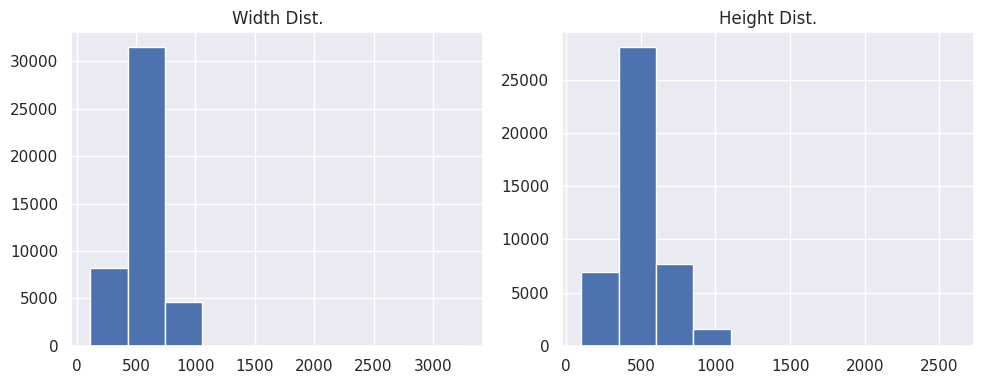

In [19]:
statement_dimension_data = f"""
SELECT
	width,
	height
FROM {database_name}.{manifest_table}
"""

dimension_data = pd.read_sql(statement_dimension_data, engine)
dimension_data.head()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(dimension_data["width"])
ax[0].set_title("Width Dist.")

ax[1].hist(dimension_data["height"])
ax[1].set_title("Height Dist.")

plt.tight_layout()
plt.show()

In [20]:
%store database_name
%store manifest_table    
%store landmarks_table 
%store s3_staging_dir

Stored 'database_name' (str)
Stored 'manifest_table' (str)
Stored 'landmarks_table' (str)
Stored 's3_staging_dir' (str)
